# Detección de la enfermedad tiña en vacas
dataset de imágenes

In [22]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from PIL import Image
from pathlib import Path
from google.colab import files
import io

from sklearn.model_selection import train_test_split, learning_curve, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

import tensorflow as tf

import matplotlib.pyplot as plt
import seaborn as sns

carpeta = "/content/drive/MyDrive/cows"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Sustentación #1


In [ ]:
print(os.listdir("/content/drive/MyDrive/cows/ambos"))

['img1022.jpg', 'img1023.jpg', 'img1024.jpg', 'img1025.jpg', 'img1026.jpg', 'img1027.jpg', 'img1028.jpg', 'img1029.jpg', 'img1030.jpg', 'img1031.jpg', 'img1032.jpg', 'img1033.jpg', 'img1034.jpg', 'img1035.jpg', 'img1036.jpg', 'img1037.jpg', 'img1038.jpg', 'img1039.jpg', 'img1040.jpg', 'img1041.jpg', 'img1042.jpg', 'img1043.jpg', 'img1044.jpg', 'img1045.jpg', 'img1046.jpg', 'img1047.jpg', 'img1048.jpg', 'img1049.jpg', 'img1050.jpg', 'img1051.jpg', 'img1052.jpg', 'img1053.jpg', 'img1054.jpg', 'img1055.jpg', 'img1056.jpg', 'img1057.jpg', 'img1058.jpg', 'img1059.jpg', 'img1060.jpg', 'img1061.jpg', 'img1062.jpg', 'img1063.jpg', 'img1064.jpg', 'img1065.jpg', 'img1066.jpg', 'img1067.jpg', 'img1068.jpg', 'img1069.jpg', 'img1070.jpg', 'img1071.jpg', 'imgs366.jpg', 'imgs474.jpg', 'imgs475.jpg', 'imgs476.jpg', 'imgs477.jpg', 'imgs478.jpg', 'imgs479.jpg', 'imgs480.jpg', 'imgs481.jpg', 'imgs482.jpg', 'imgs483.jpg', 'imgs484.jpg', 'imgs485.jpg', 'imgs486.jpg', 'imgs487.jpg', 'imgs488.jpg', 'imgs489.

In [ ]:
imgs = []

for nombre in os.listdir(carpeta+"/ambos"):
    imagen = Image.open(os.path.join(carpeta+"/ambos", nombre))
    imagen = np.array(imagen, dtype=np.float32)
    imagen = imagen/255
    imgs.append(imagen)

# Comprobar tamaños
tamanos = [img.shape for img in imgs]

if len(set(tamanos)) != 1:
    raise ValueError("Cada imagen debe tener igual dimensiones.")

# Crear matriz:
# (número de imágenes, alto, ancho)
imagenes = np.stack(imgs)

print("Dimensiones:", imagenes.shape)

Dimensiones: (100, 100, 100, 3)


In [ ]:
promedio = np.mean(imagenes, axis=0)
desviacion = np.std(imagenes, axis=0)

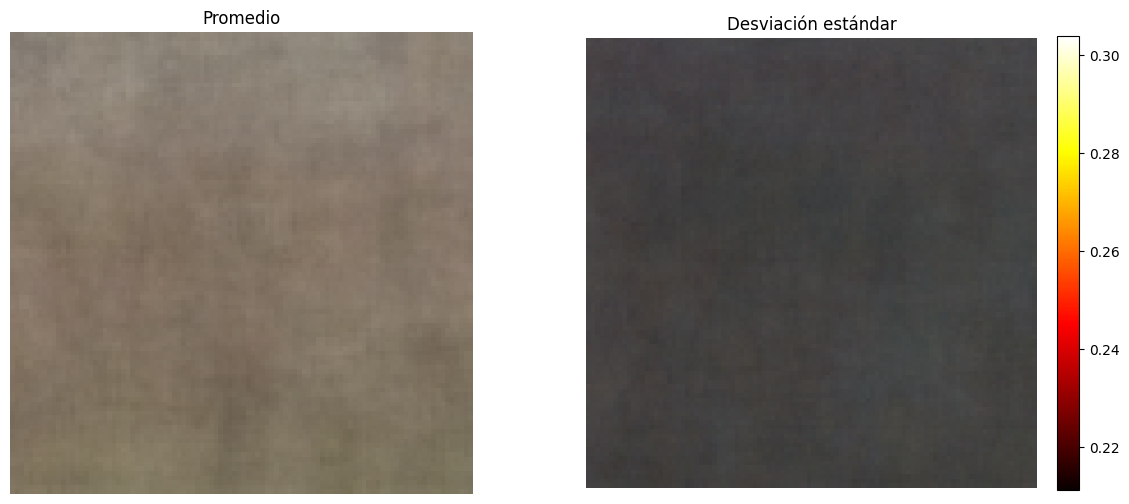

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

#Mostrar promedio
ax[0].imshow(promedio, cmap="gray", vmin=promedio.min(), vmax=promedio.max())
ax[0].set_title("Promedio")
ax[0].axis("off")

# Mostrar desviación - scaled to its actual data range
im = ax[1].imshow(desviacion, cmap="hot", vmin=desviacion.min(), vmax=desviacion.max())
ax[1].set_title("Desviación estándar")
ax[1].axis("off")

fig.colorbar(im, ax=ax[1], fraction=0.046, pad=0.04)

plt.show()

# Sustentación #2

In [ ]:
clases = {
    "healthycows": 0,
    "lumpycows": 1
}

x = []
y = []

for carpeta2, label in clases.items():

    camino = os.path.join(carpeta, carpeta2)

    for nombre in os.listdir(camino):

        camino_imagen = os.path.join(camino, nombre)

        img = Image.open(camino_imagen)
        img = img.convert("L")
        img = img.resize((100, 100))

        array_img = np.array(img)

        x.append(array_img)
        y.append(label)

x = np.array(x)
y = np.array(y)

print("Dimensiones de x:", x.shape)
print("Dimensiones de y:", y.shape)

print("Total de imágenes:", len(x))
print("Vacas sanas:", np.sum(y == 0))
print("Vacas enfermas:", np.sum(y == 1))

Dimensiones de x: (100, 100, 100)
Dimensiones de y: (100,)
Total de imágenes: 100
Vacas sanas: 50
Vacas enfermas: 50


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Imágenes de entrenamiento:", len(x_train))
print("Imágenes de prueba:", len(x_test))

Imágenes de entrenamiento: 80
Imágenes de prueba: 20


In [ ]:
x_train_flat = np.array([img.flatten() for img in x_train])
x_test_flat = np.array([img.flatten() for img in x_test])
print("# de Datos:", x_train_flat.shape)

# de Datos: (80, 10000)


In [ ]:
models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(kernel="poly",degree=3 ,gamma=2))
    ])
}

results = {}

for name, model in models.items():

    print(f"Entrenando {name}...")

    model.fit(x_train_flat, y_train)

    predictions = model.predict(x_test_flat)

    accuracy = accuracy_score(y_test, predictions)

    results[name] = accuracy

    print(f"Accuracy de {name}: {accuracy:.4f}")
    print("-" * 40)

Entrenando Decision Tree...
Accuracy de Decision Tree: 0.6000
----------------------------------------
Entrenando Random Forest...
Accuracy de Random Forest: 0.5000
----------------------------------------
Entrenando SVM...
Accuracy de SVM: 0.6000
----------------------------------------


In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

learning_results = {}

for name, model in models.items():

    print(f"Calculando curva de aprendizaje: {name}")

    train_sizes, train_scores, validation_scores = learning_curve(
        model,
        x_train_flat,
        y_train,
        train_sizes=np.linspace(0.2, 1.0, 5),
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    learning_results[name] = {
        "train_sizes": train_sizes,
        "train_scores": train_scores,
        "validation_scores": validation_scores
    }

Calculando curva de aprendizaje: Decision Tree
Calculando curva de aprendizaje: Random Forest
Calculando curva de aprendizaje: SVM


In [ ]:
arquitectura = [64, 64, 128, 128, 256, 256]

print(f"\n{name}")

dl = tf.keras.Sequential()

dl.add(tf.keras.layers.Input(shape=(10000,)))

# Capas ocultas
for neuronas in arquitectura:
    dl.add(
        tf.keras.layers.Dense(neuronas, activation='relu')
    )

# Capa de salida
dl.add(
    tf.keras.layers.Dense(1, activation='sigmoid')
)

dl.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history = dl.fit(
    x_train_flat,
    y_train,
    epochs=30,
    batch_size=8,
    validation_split=0.2,
    verbose=1
)

dl_predict = dl.predict(x_test_flat)
results["Deep Learning"] = accuracy_score(y_test,(dl_predict >= 0.5).astype(int).flatten())


10 Capas
Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5938 - loss: 12.8574 - val_accuracy: 0.3750 - val_loss: 24.9582
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5000 - loss: 7.5518 - val_accuracy: 0.5625 - val_loss: 0.9487
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3750 - loss: 9.0475 - val_accuracy: 0.6250 - val_loss: 1.0712
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5469 - loss: 5.2454 - val_accuracy: 0.3750 - val_loss: 11.3661
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5938 - loss: 3.3850 - val_accuracy: 0.6250 - val_loss: 5.2301
Epoch 6/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4688 - loss: 4.2798 - val_accuracy: 0.6250 - val_loss: 2.3409
Epoch 7/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4062 - loss: 7.0323 - val_accuracy: 0.3750 - val_loss: 8.8459
Epoch 8/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.5000 - loss: 3.3832 - val_accuracy: 0.3750 - val_

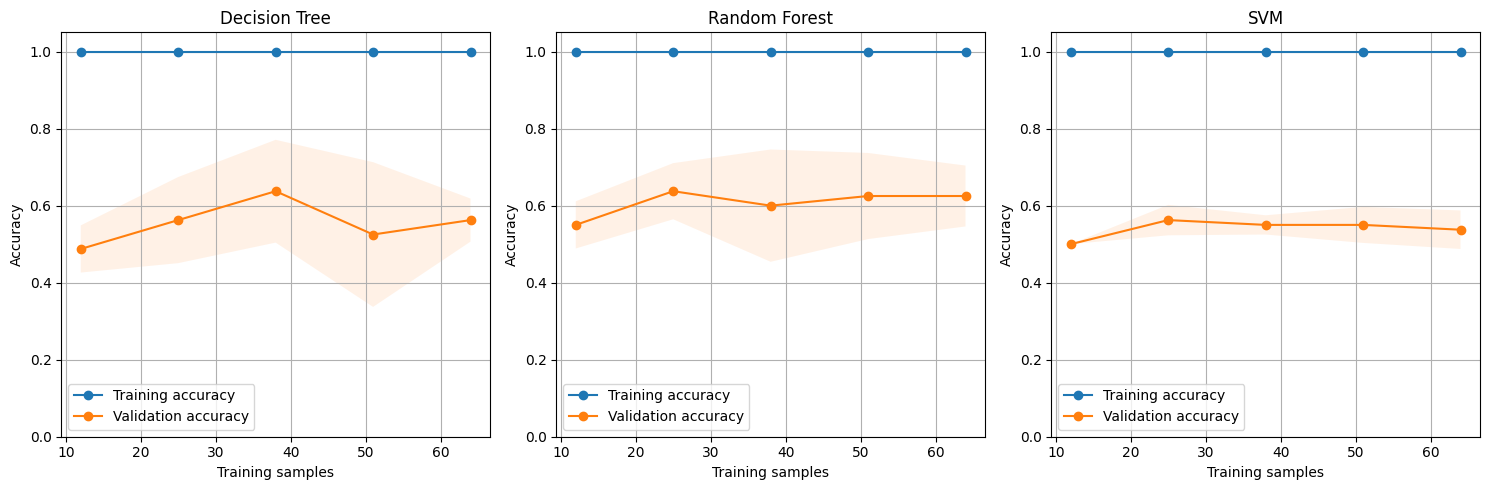

In [ ]:
plt.figure(figsize=(15, 5))

for i, (name, data) in enumerate(learning_results.items(), 1):

    plt.subplot(1, 3, i)

    train_mean = data["train_scores"].mean(axis=1)
    val_mean = data["validation_scores"].mean(axis=1)

    train_std = data["train_scores"].std(axis=1)
    val_std = data["validation_scores"].std(axis=1)

    plt.plot(data["train_sizes"], train_mean, marker='o',
             label="Training accuracy")

    plt.plot(data["train_sizes"], val_mean, marker='o',
             label="Validation accuracy")

    plt.fill_between(
        data["train_sizes"],
        train_mean - train_std,
        train_mean + train_std,
        alpha=0.1
    )

    plt.fill_between(
        data["train_sizes"],
        val_mean - val_std,
        val_mean + val_std,
        alpha=0.1
    )

    plt.title(name)
    plt.xlabel("Training samples")
    plt.ylabel("Accuracy")
    plt.ylim(0, 1.05)
    plt.legend()
    plt.grid()

plt.tight_layout()
plt.show()

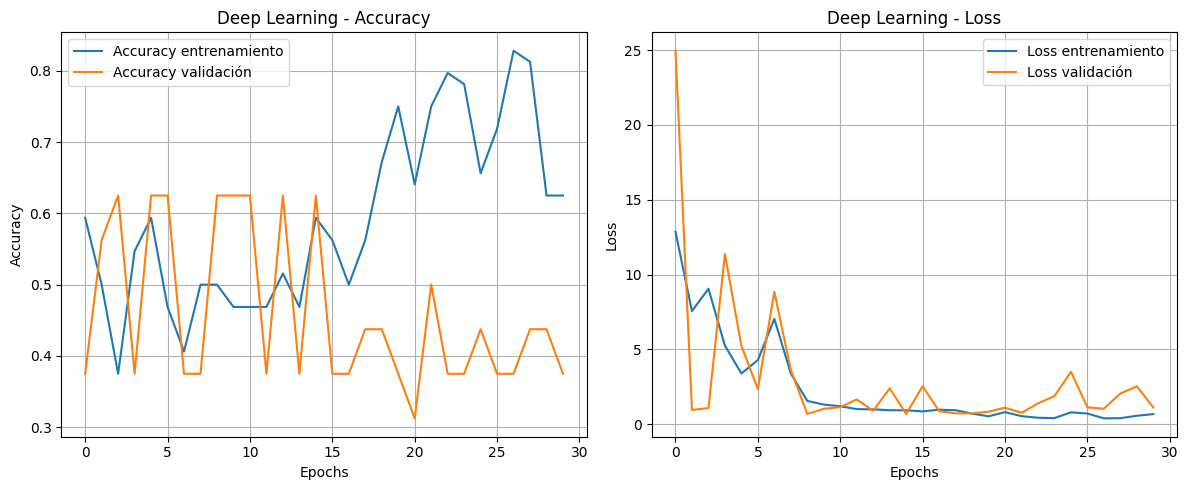

In [ ]:
plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(history.history['accuracy'], label='Accuracy entrenamiento')
plt.plot(history.history['val_accuracy'], label='Accuracy validación')

plt.title('Deep Learning - Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(history.history['loss'], label='Loss entrenamiento')
plt.plot(history.history['val_loss'], label='Loss validación')

plt.title('Deep Learning - Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

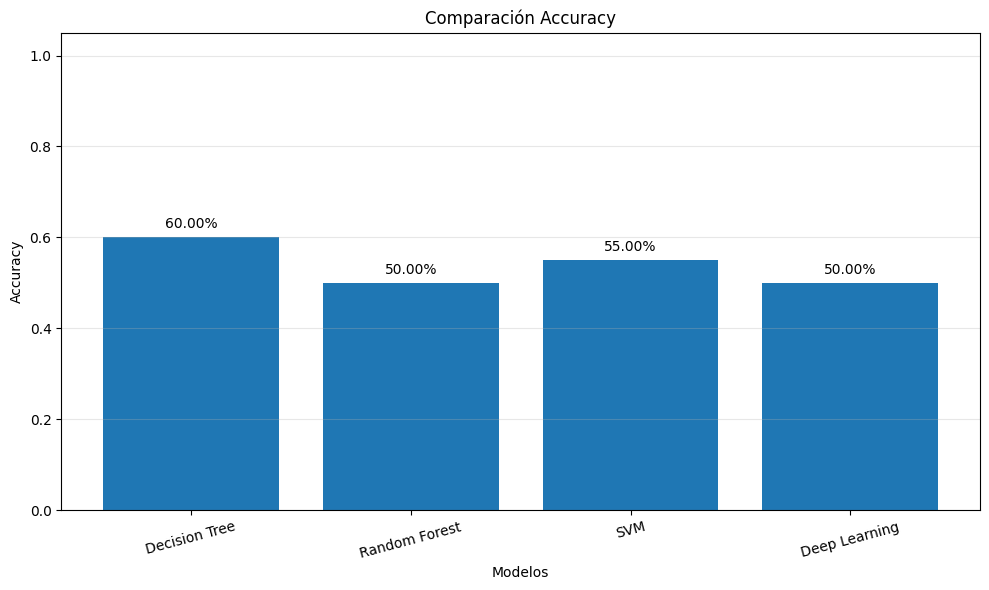

In [ ]:
plt.figure(figsize=(10, 6))

model_names = list(results.keys())
accuracies = list(results.values())

bars = plt.bar(
    model_names,
    accuracies
)

plt.title("Comparación Accuracy")
plt.xlabel("Modelos")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

plt.xticks(rotation=15)

for bar, accuracy in zip(bars, accuracies):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{accuracy:.2%}",
        ha='center'
    )

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Sustentación Final

Aquí hacemos uso de machine learning no supervisado sobre el dataset de imagenes de vacas con la enfermedad Tiña


---



**Filtramos el dataset para usar 50 imagenes**


---

separamos las clases de imagenes para comparar los resultados al final

In [14]:
# Rutas de las clases
rutas = {
    "healthycows": "/content/drive/MyDrive/cows/healthycows",
    "lumpycows": "/content/drive/MyDrive/cows/lumpycows"
}

imagenes = []
clases_reales = []

for nombre_clase, ruta in rutas.items():

    archivos = []

    for extension in ["*.jpg", "*.jpeg", "*.png"]:
        archivos.extend(Path(ruta).glob(extension))

    archivos = sorted(archivos)

    for archivo in archivos:

        img = Image.open(archivo).convert("RGB")
        img = img.resize((100, 100))

        imagenes.append(np.array(img).flatten())

        # healthycows = 0, lumpycows = 1
        clases_reales.append(
            0 if nombre_clase == "healthycows" else 1
        )

X = np.array(imagenes)
y_real = np.array(clases_reales)

print("Dimensiones:", X.shape)
print("Clases reales:", y_real.shape)

print("Vacas saludables:", np.sum(y_real == 0))
print("Vacas enfermas:", np.sum(y_real == 1))

Dimensiones: (100, 30000)
Clases reales: (100,)
Vacas saludables: 50
Vacas enfermas: 50


**Escalamiento de los datos**

In [15]:
# Escalamiento
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

**Reducimos las características solamente a 2 componentes con PCA**

In [16]:
# PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Varianza explicada PCA:",
      pca.explained_variance_ratio_.sum())

Varianza explicada PCA: 0.3853784556391639


**probamos la misma reducción con t-SNE**


---


perplexity tiene que ser menor que el numero de imagenes por eso usamos un valor de 30

In [17]:
# t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

**Usamos k-means en cada set de datos y podemos ver la diferencia en los dos tipos de reducción**

In [18]:
kmeans_pca = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_tsne = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_kmeans_pca = kmeans_pca.fit_predict(X_pca)

labels_kmeans_tsne = kmeans_tsne.fit_predict(X_tsne)

print("K-Means PCA:")
print(labels_kmeans_pca)

print("\nK-Means t-SNE:")
print(labels_kmeans_tsne)

K-Means PCA:
[1 0 0 0 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 0 1 0 1 1
 0 1 1 1 1 0 1 0 1 1 0 0 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 0 0 1 0 1 0 1 1 1
 0 0 1 1 1 0 0 0 1 1 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1]

K-Means t-SNE:
[1 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 0 1 1 1 1 0 1 0 0 1 1 0 1 1 1 0 0 1 0 1 0
 0 1 1 1 1 0 1 0 1 1 0 0 1 1 1 1 0 1 1 0 1 0 0 1 1 1 1 1 0 0 0 0 0 0 1 1 1
 0 0 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 0 0 1 1 0 0 1 1]


**Definimos una función de busqueda de los parametros optimos para usar en cuanto a dbscan**


---

seguidamente la utilizamos para los dos tipos de reducción de datos

In [23]:
def buscar_dbscan(X, min_coverage=0.20):

    resultados = []

    mejor_modelo = None
    mejor_score = -np.inf
    mejores_parametros = None

    # Probar diferentes cantidades de vecinos
    valores_min_samples = range(2, 11)

    # Obtener distancias a los vecinos
    vecinos = NearestNeighbors(n_neighbors=10)
    vecinos.fit(X)

    distancias, _ = vecinos.kneighbors(X)

    for min_samples in valores_min_samples:

        # Distancia al vecino correspondiente
        distancias_k = np.sort(distancias[:, min_samples - 1])

        # Generar eps según las distancias observadas
        valores_eps = np.unique(
            np.quantile(
                distancias_k,
                np.linspace(0.05, 0.95, 40)
            )
        )

        for eps in valores_eps:

            modelo = DBSCAN(
                eps=float(eps),
                min_samples=min_samples
            )

            labels = modelo.fit_predict(X)

            # Cantidad de puntos que no son ruido
            mascara = labels != -1
            cobertura = np.mean(mascara)

            etiquetas_validas = labels[mascara]
            datos_validos = X[mascara]

            clusters = np.unique(etiquetas_validas)
            n_clusters = len(clusters)

            # Tamaño del cluster más pequeño
            tamanos = [
                np.sum(etiquetas_validas == c)
                for c in clusters
            ]

            score = None
            score_ajustado = None

            # Evaluar únicamente soluciones válidas
            if (
                n_clusters >= 2
                and n_clusters < len(datos_validos)
                and cobertura >= min_coverage
                and min(tamanos) >= 2
            ):

                score = silhouette_score(
                    datos_validos,
                    etiquetas_validas
                )

                # Considerar también el porcentaje de ruido
                score_ajustado = (
                    score * cobertura
                )

                if score_ajustado > mejor_score:

                    mejor_score = score_ajustado
                    mejores_parametros = {
                        "eps": float(eps),
                        "min_samples": min_samples
                    }
                    mejor_modelo = modelo

            resultados.append({
                "eps": float(eps),
                "min_samples": min_samples,
                "clusters": n_clusters,
                "ruido": np.sum(labels == -1),
                "cobertura": cobertura,
                "silhouette": score,
                "score_ajustado": score_ajustado
            })

    df_resultados = pd.DataFrame(resultados)

    if mejor_modelo is None:

        print("No se encontró una configuración válida.")
        print("Revisa los resultados o reduce min_coverage.")
        print("\nConfiguraciones con mayor cobertura:")

        print(
            df_resultados.sort_values(
                "cobertura",
                ascending=False
            ).head(10).to_string(index=False)
        )

        return {
            "modelo": None,
            "parametros": None,
            "resultados": df_resultados
        }

    print("Mejor configuración encontrada:")
    print("eps:", mejores_parametros["eps"])
    print("min_samples:", mejores_parametros["min_samples"])
    print("Silhouette:", df_resultados[
        (df_resultados["eps"] == mejores_parametros["eps"]) &
        (df_resultados["min_samples"] == mejores_parametros["min_samples"])
    ]["silhouette"].iloc[0])

    return {
        "modelo": mejor_modelo,
        "parametros": mejores_parametros,
        "resultados": df_resultados
    }

print("BUSCANDO DBSCAN PARA PCA")

resultado_pca = buscar_dbscan(X_pca)

print("\nBUSCANDO DBSCAN PARA t-SNE")

resultado_tsne = buscar_dbscan(X_tsne)

BUSCANDO DBSCAN PARA PCA
Mejor configuración encontrada:
eps: 3.489486457096658
min_samples: 2
Silhouette: 0.5779506847976114

BUSCANDO DBSCAN PARA t-SNE
Mejor configuración encontrada:
eps: 1.1444115571120086
min_samples: 10
Silhouette: 0.46203479170799255


In [24]:
dbscan_pca = resultado_pca["modelo"]
dbscan_tsne = resultado_tsne["modelo"]

labels_dbscan_pca = (
    dbscan_pca.labels_
    if dbscan_pca is not None
    else None
)

labels_dbscan_tsne = (
    dbscan_tsne.labels_
    if dbscan_tsne is not None
    else None
)

/tmp/ipykernel_2296/3145017593.py:51: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap("tab10", max(len(valores), 1))


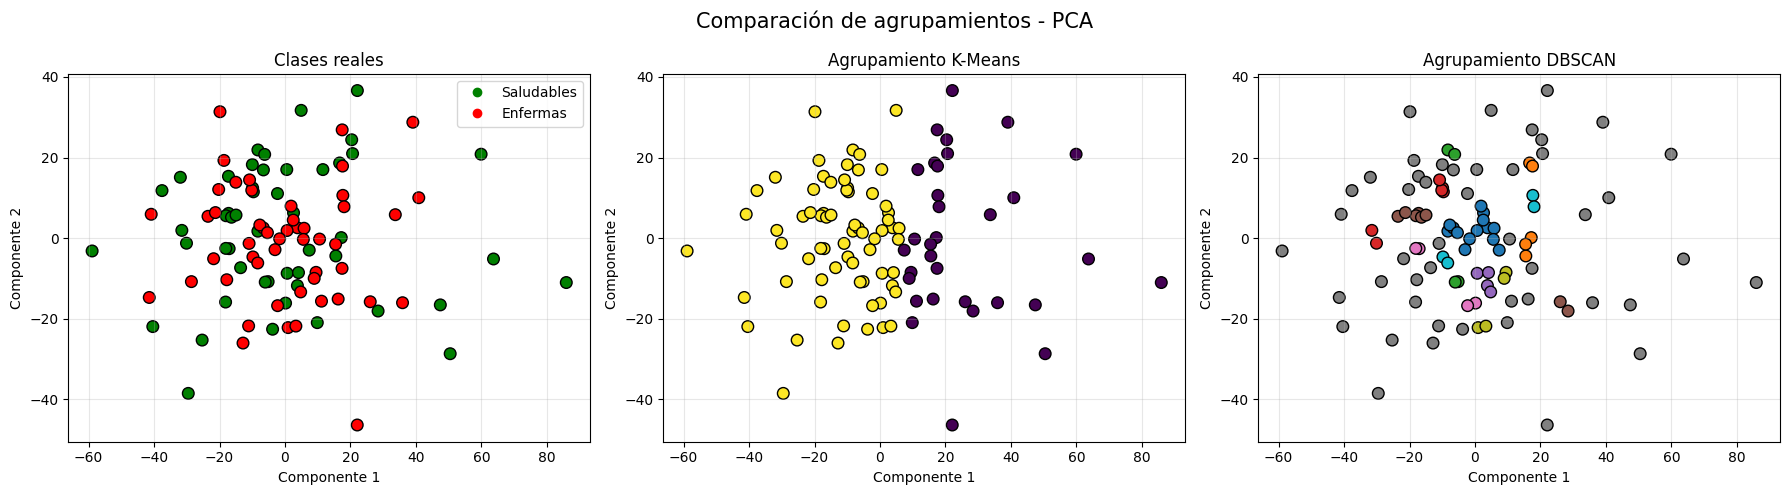

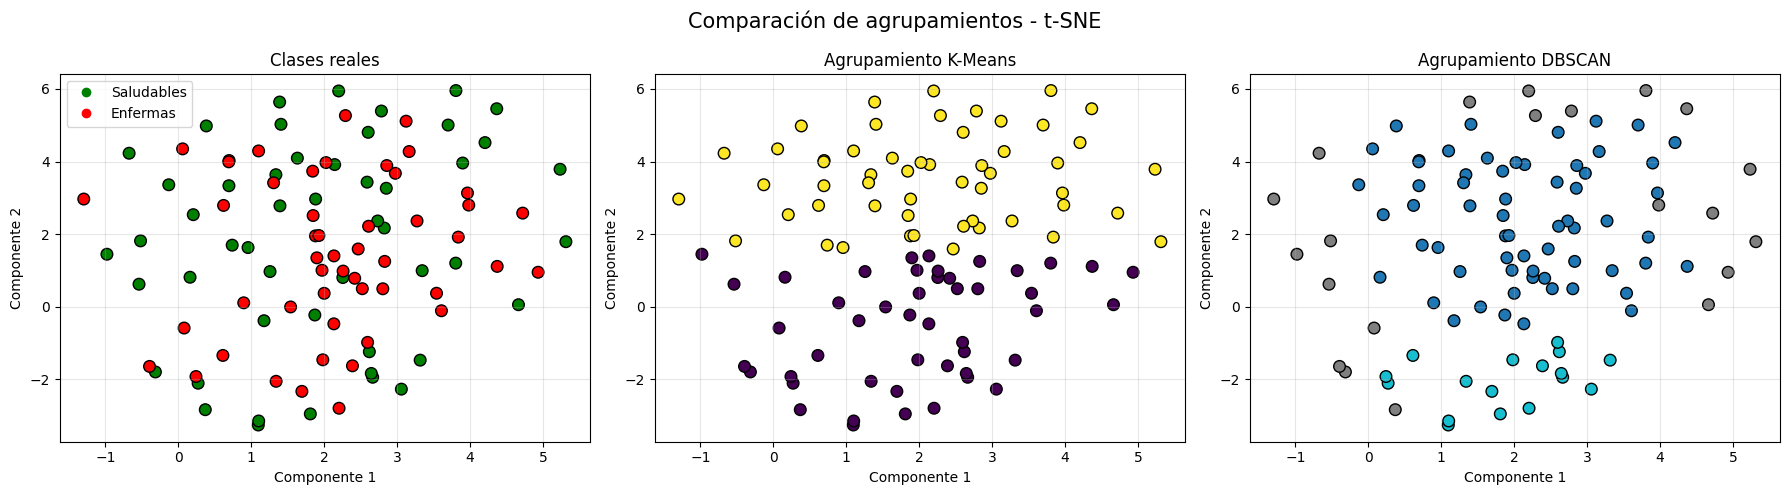

In [26]:
def graficar_comparacion(X, y_real, labels_kmeans,
                         labels_dbscan, nombre):

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # 1. Distribución de las clases reales
    axes[0].scatter(
        X[:, 0],
        X[:, 1],
        c=y_real,
        cmap=plt.matplotlib.colors.ListedColormap(
            ["green", "red"]
        ),
        s=70,
        edgecolors="black"
    )

    axes[0].set_title("Clases reales")
    axes[0].legend(
        handles=[
            plt.Line2D([], [], marker="o", linestyle="",
                       color="green", label="Saludables"),
            plt.Line2D([], [], marker="o", linestyle="",
                       color="red", label="Enfermas")
        ]
    )

    # 2. K-Means
    axes[1].scatter(
        X[:, 0],
        X[:, 1],
        c=labels_kmeans,
        cmap="viridis",
        s=70,
        edgecolors="black"
    )

    axes[1].set_title("Agrupamiento K-Means")

    # 3. DBSCAN
    if labels_dbscan is not None:

        colores = [
            "gray" if label == -1 else None
            for label in labels_dbscan
        ]

        # Los clusters reciben colores automáticos
        valores = sorted(set(labels_dbscan) - {-1})

        cmap = plt.cm.get_cmap("tab10", max(len(valores), 1))

        colores_finales = [
            "gray" if label == -1
            else cmap(valores.index(label))
            for label in labels_dbscan
        ]

        axes[2].scatter(
            X[:, 0],
            X[:, 1],
            c=colores_finales,
            s=70,
            edgecolors="black"
        )

        axes[2].set_title("Agrupamiento DBSCAN")

    else:
        axes[2].text(
            0.5, 0.5,
            "No se encontró una configuración válida",
            ha="center",
            va="center"
        )

        axes[2].set_title("DBSCAN")

    for ax in axes:
        ax.set_xlabel("Componente 1")
        ax.set_ylabel("Componente 2")
        ax.grid(alpha=0.3)

    plt.suptitle(f"Comparación de agrupamientos - {nombre}",
                 fontsize=15)

    plt.tight_layout()
    plt.show()

# PCA
graficar_comparacion(
    X_pca,
    y_real,
    labels_kmeans_pca,
    labels_dbscan_pca,
    "PCA"
)

# t-SNE
graficar_comparacion(
    X_tsne,
    y_real,
    labels_kmeans_tsne,
    labels_dbscan_tsne,
    "t-SNE"
)

In [29]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

resultados_finales = []

modelos = [
    ("PCA + K-Means", X_pca, labels_kmeans_pca),
    ("PCA + DBSCAN", X_pca, labels_dbscan_pca),
    ("t-SNE + K-Means", X_tsne, labels_kmeans_tsne),
    ("t-SNE + DBSCAN", X_tsne, labels_dbscan_tsne)
]

for nombre, X_reducido, labels in modelos:

    if labels is None:
        continue

    ari = adjusted_rand_score(y_real, labels)
    nmi = normalized_mutual_info_score(y_real, labels)

    n_clusters = len(set(labels) - {-1})
    ruido = np.sum(labels == -1)

    resultados_finales.append({
        "Método": nombre,
        "Clusters": n_clusters,
        "Puntos ruido": ruido,
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4)
    })

df_final = pd.DataFrame(resultados_finales)

display(df_final)

,Método,Clusters,Puntos ruido,ARI,NMI
0,PCA + K-Means,2,0,-0.0073,0.0014
1,PCA + DBSCAN,19,43,0.0012,0.1078
2,t-SNE + K-Means,2,0,-0.0001,0.0073
3,t-SNE + DBSCAN,2,21,0.0120,0.0215


**Conclusiones**


---
**PCA:**
Al aplicar PCA para reducir las 30.000 características originales de cada imagen a dos componentes principales, se obtuvo una representación bidimensional que permitió visualizar la distribución de las vacas saludables y enfermas.

En la distribución de las clases reales se observa una considerable superposición entre ambas categorías, por lo que no existe una separación visual claramente definida.

Al aplicar K-Means con dos clústeres, se obtuvo una división de los datos principalmente relacionada con su posición en la primera componente principal. Sin embargo, ambos clústeres contienen imágenes pertenecientes a las dos clases reales, por lo que no se observa una correspondencia directa entre los grupos encontrados y las categorías de salud.

Por otra parte, DBSCAN identificó diferentes regiones de concentración de datos, pero clasificó una cantidad considerable de imágenes como ruido. Esto sugiere que la distribución de las imágenes no presenta una estructura de densidad suficientemente clara para los parámetros utilizados.

En general, los resultados muestran que la reducción a dos componentes mediante PCA no permite visualizar una separación evidente entre las vacas saludables y enfermas. Es necesario complementar este análisis con las métricas ARI y NMI y comparar los resultados con la reducción mediante t-SNE.

**t-SNE:**
Al aplicar t-SNE para reducir las dimensiones de las imágenes a dos componentes, se obtuvo una representación que permite observar diferentes regiones de concentración de datos.

Al igual que en la distribución de imágenes en PCA, los puntos no presentan una separación uniforme, en su lugar se ven dispersos aleatoriamente.

Al aplicar K-Means con dos clústeres, se identificó una división de los datos principalmente relacionada con la segunda componente de t-SNE. Aunque los grupos presentan una distribución clara, ambos contienen imágenes pertenecientes a las dos clases reales, por lo que no existe una relación directa entre los clústeres y la clasificación de imagenes.

Por otra parte, DBSCAN identificó dos regiones principales de concentración de datos y clasificó algunas imágenes como ruido. Esto indica que existen regiones con diferentes densidades en la representación obtenida mediante t-SNE. Sin embargo, los grupos encontrados tampoco representan necesariamente las categorías reales.

En comparación con PCA, t-SNE presenta regiones de agrupamiento visualmente más definidas. No obstante, esta característica no implica una mejor clasificación de las imágenes, ya que los agrupamientos encontrados no muestran una separación evidente entre las vacas saludables y enfermas.